# Local training workspace — M1 / MPS preflight

This executed notebook preserves the local hardware benchmark, reproduced data boundaries and figures. It does **not** contain a completed DistilBERT fine-tuning experiment. The repeated-batch benchmark discarded its weights and cannot demonstrate improved accuracy.

The existing model quality figures are explicitly labeled as baselines. Full fine-tuning, independent human labels and natural audio validation remain pending. Figures are exported separately as 300 dpi PNG plus vector SVG and PDF.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'results/transformer').is_dir() else Path.cwd().parent
benchmark = json.loads((ROOT / 'results/transformer/local_hardware_benchmark.json').read_text())
manifest = json.loads((ROOT / 'results/transformer/data_manifest.json').read_text())
display(pd.Series({k: benchmark[k] for k in ['device','model','revision','batch_size','padded_max_length','precision','examples_per_second','mps_driver_memory_GiB','estimated_training_only_minutes_per_epoch']}))
display(pd.DataFrame(manifest['parts']).T)
print('Exact original test boundary retained: 22,921 comments.')
print('Training-only validation: 9,169 comments; fitting pool: 82,513.')
print('One audit-matching training input excluded.')


device                                                                            mps
model                                              distilbert/distilbert-base-uncased
revision                                     12040accade4e8a0f71eabdb258fecc2e7e948be
batch_size                                                                          4
padded_max_length                                                                 128
precision                                                                     float32
examples_per_second                                                          16.28196
mps_driver_memory_GiB                                                        2.174515
estimated_training_only_minutes_per_epoch                                   84.462599
dtype: object

,rows,attacks,sha256,revision_ids_sha256
fit,82513,9642,d619f66f87e04c25ad208861198a4ec935ee17bab20117...,487a256be0bba2fac050d35938776036bb53f0b5b4b3ca...
validation,9169,1071,d56047c57ba70b5f4e119519bd6c466b1280e14421aeab...,cb8576f9b536d3d6452882fd6a1dd91ef86a30237d8e9c...
test,22921,2679,f1a1b3f77b75d9d6189e197d78def698b3f708e5f31dfc...,fa34e1411f7980bd314dec307bae90d669db791932263b...


Exact original test boundary retained: 22,921 comments.
Training-only validation: 9,169 comments; fitting pool: 82,513.
One audit-matching training input excluded.


## Measured evidence and exported figures

The time estimate extrapolates six short measured steps after warm-up. Validation, tokenization, checkpoint I/O, longer sequences, memory pressure and thermal effects can change total runtime. It is not a measured full-epoch duration.


### Candidate data partitions; no test input used for fitting.


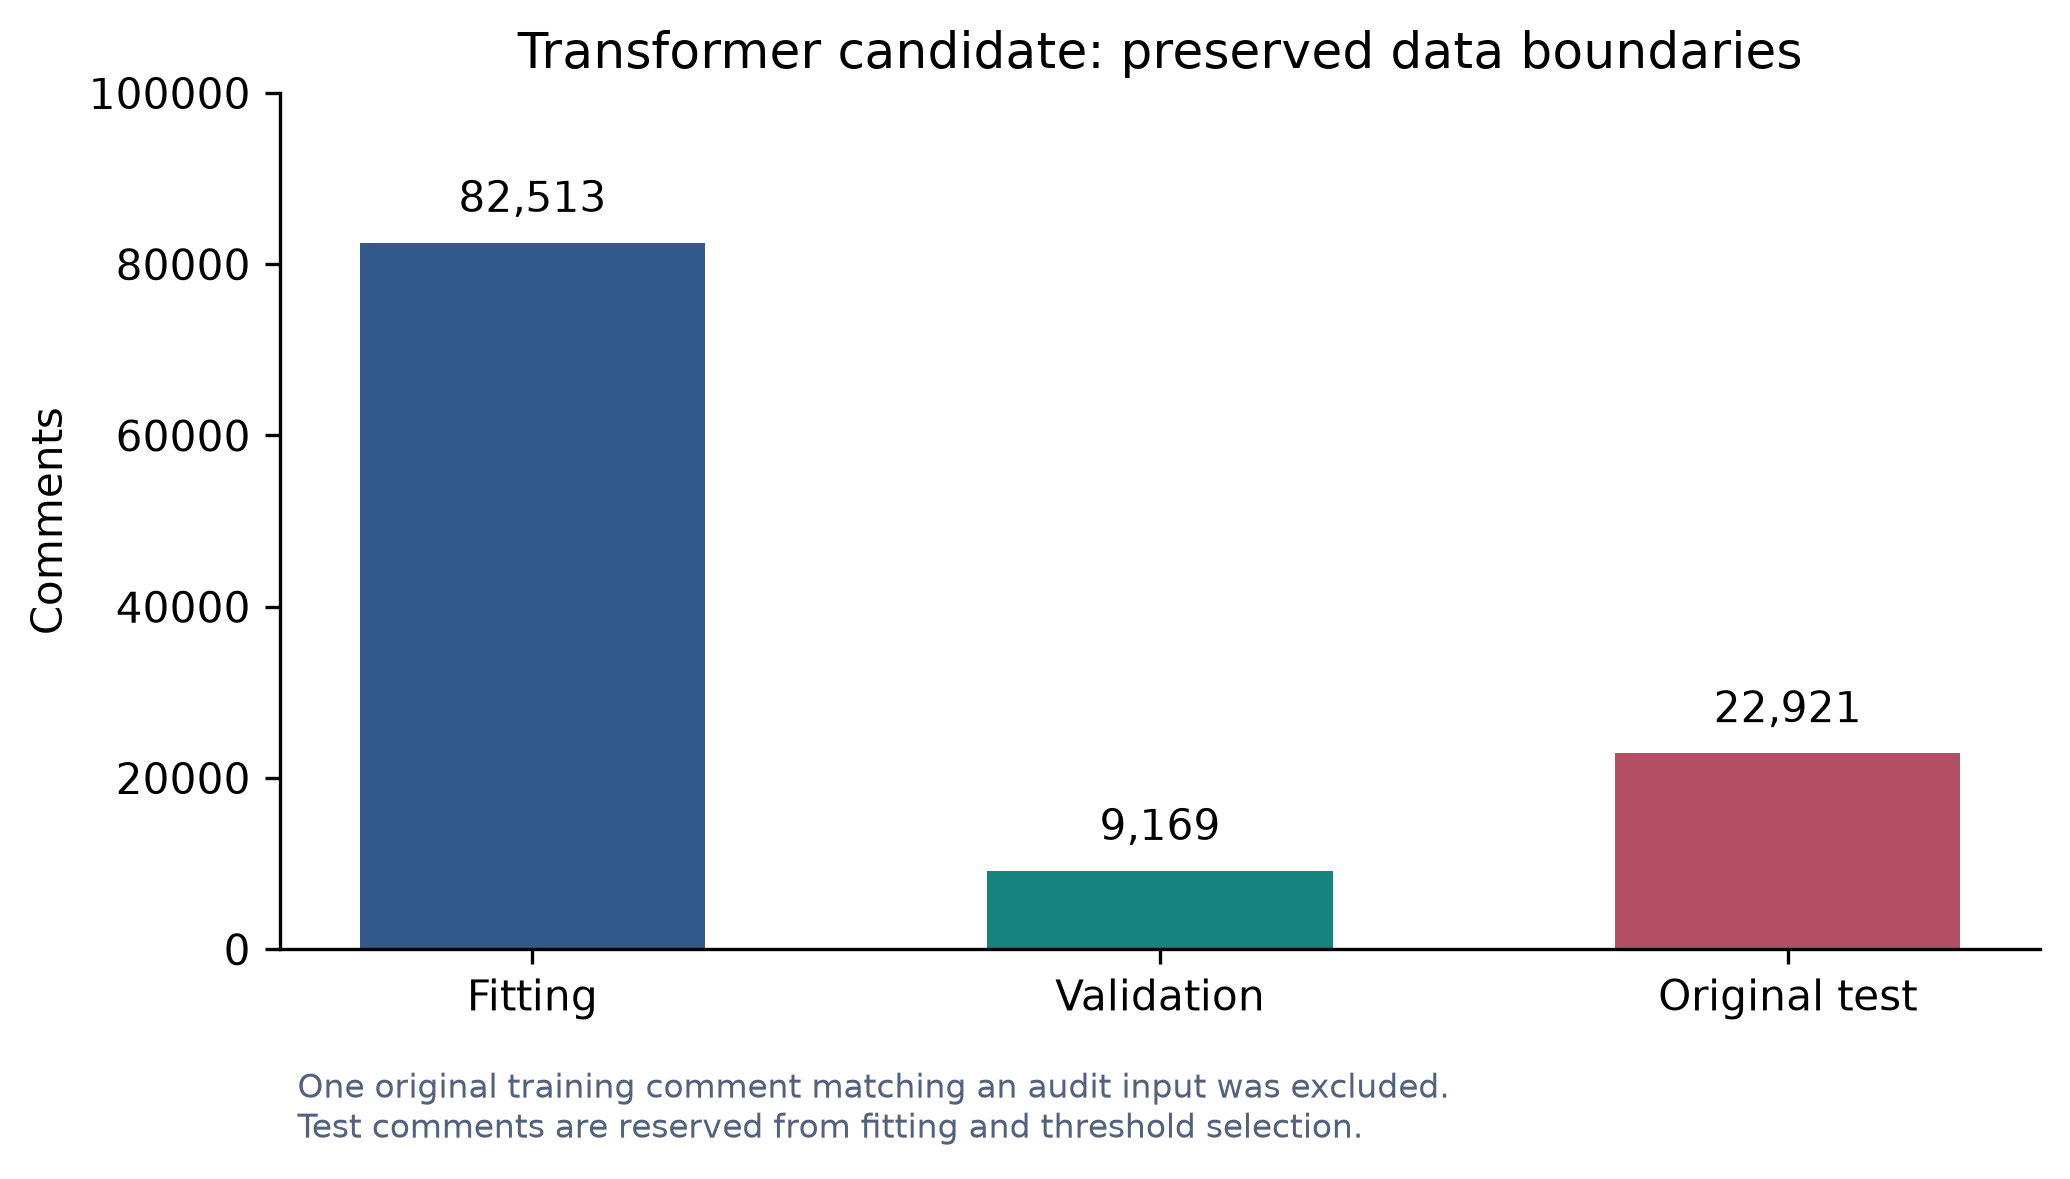

In [2]:
display(Image(filename=str(ROOT / 'reports/figures/transformer_data_partitions.png'), width=900))


### Existing classical baselines; no DistilBERT quality result is shown.


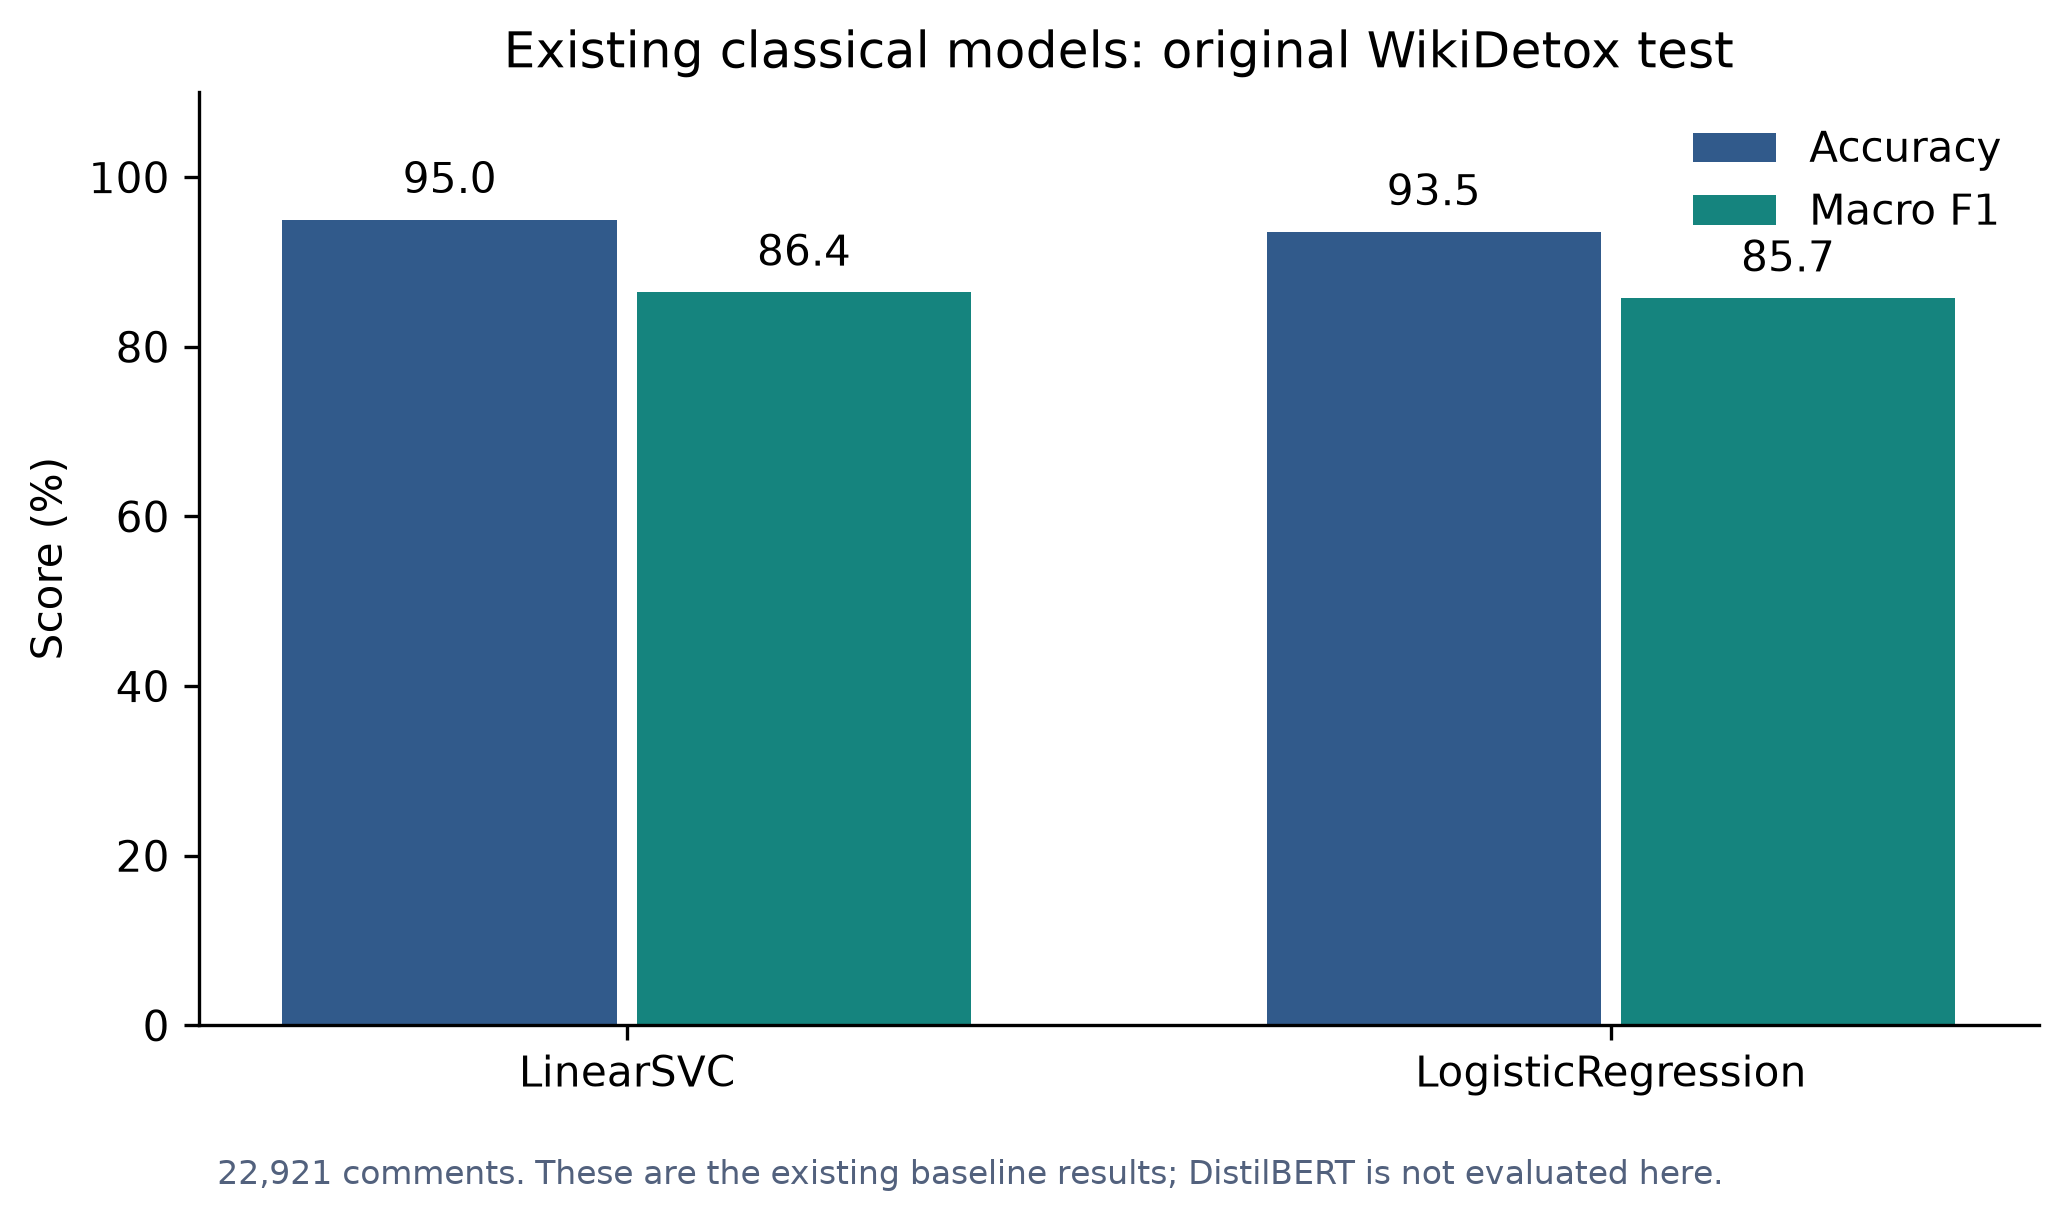

In [3]:
display(Image(filename=str(ROOT / 'reports/figures/existing_classical_model_comparison.png'), width=900))


### Current attack detector errors; authored diagnostic.


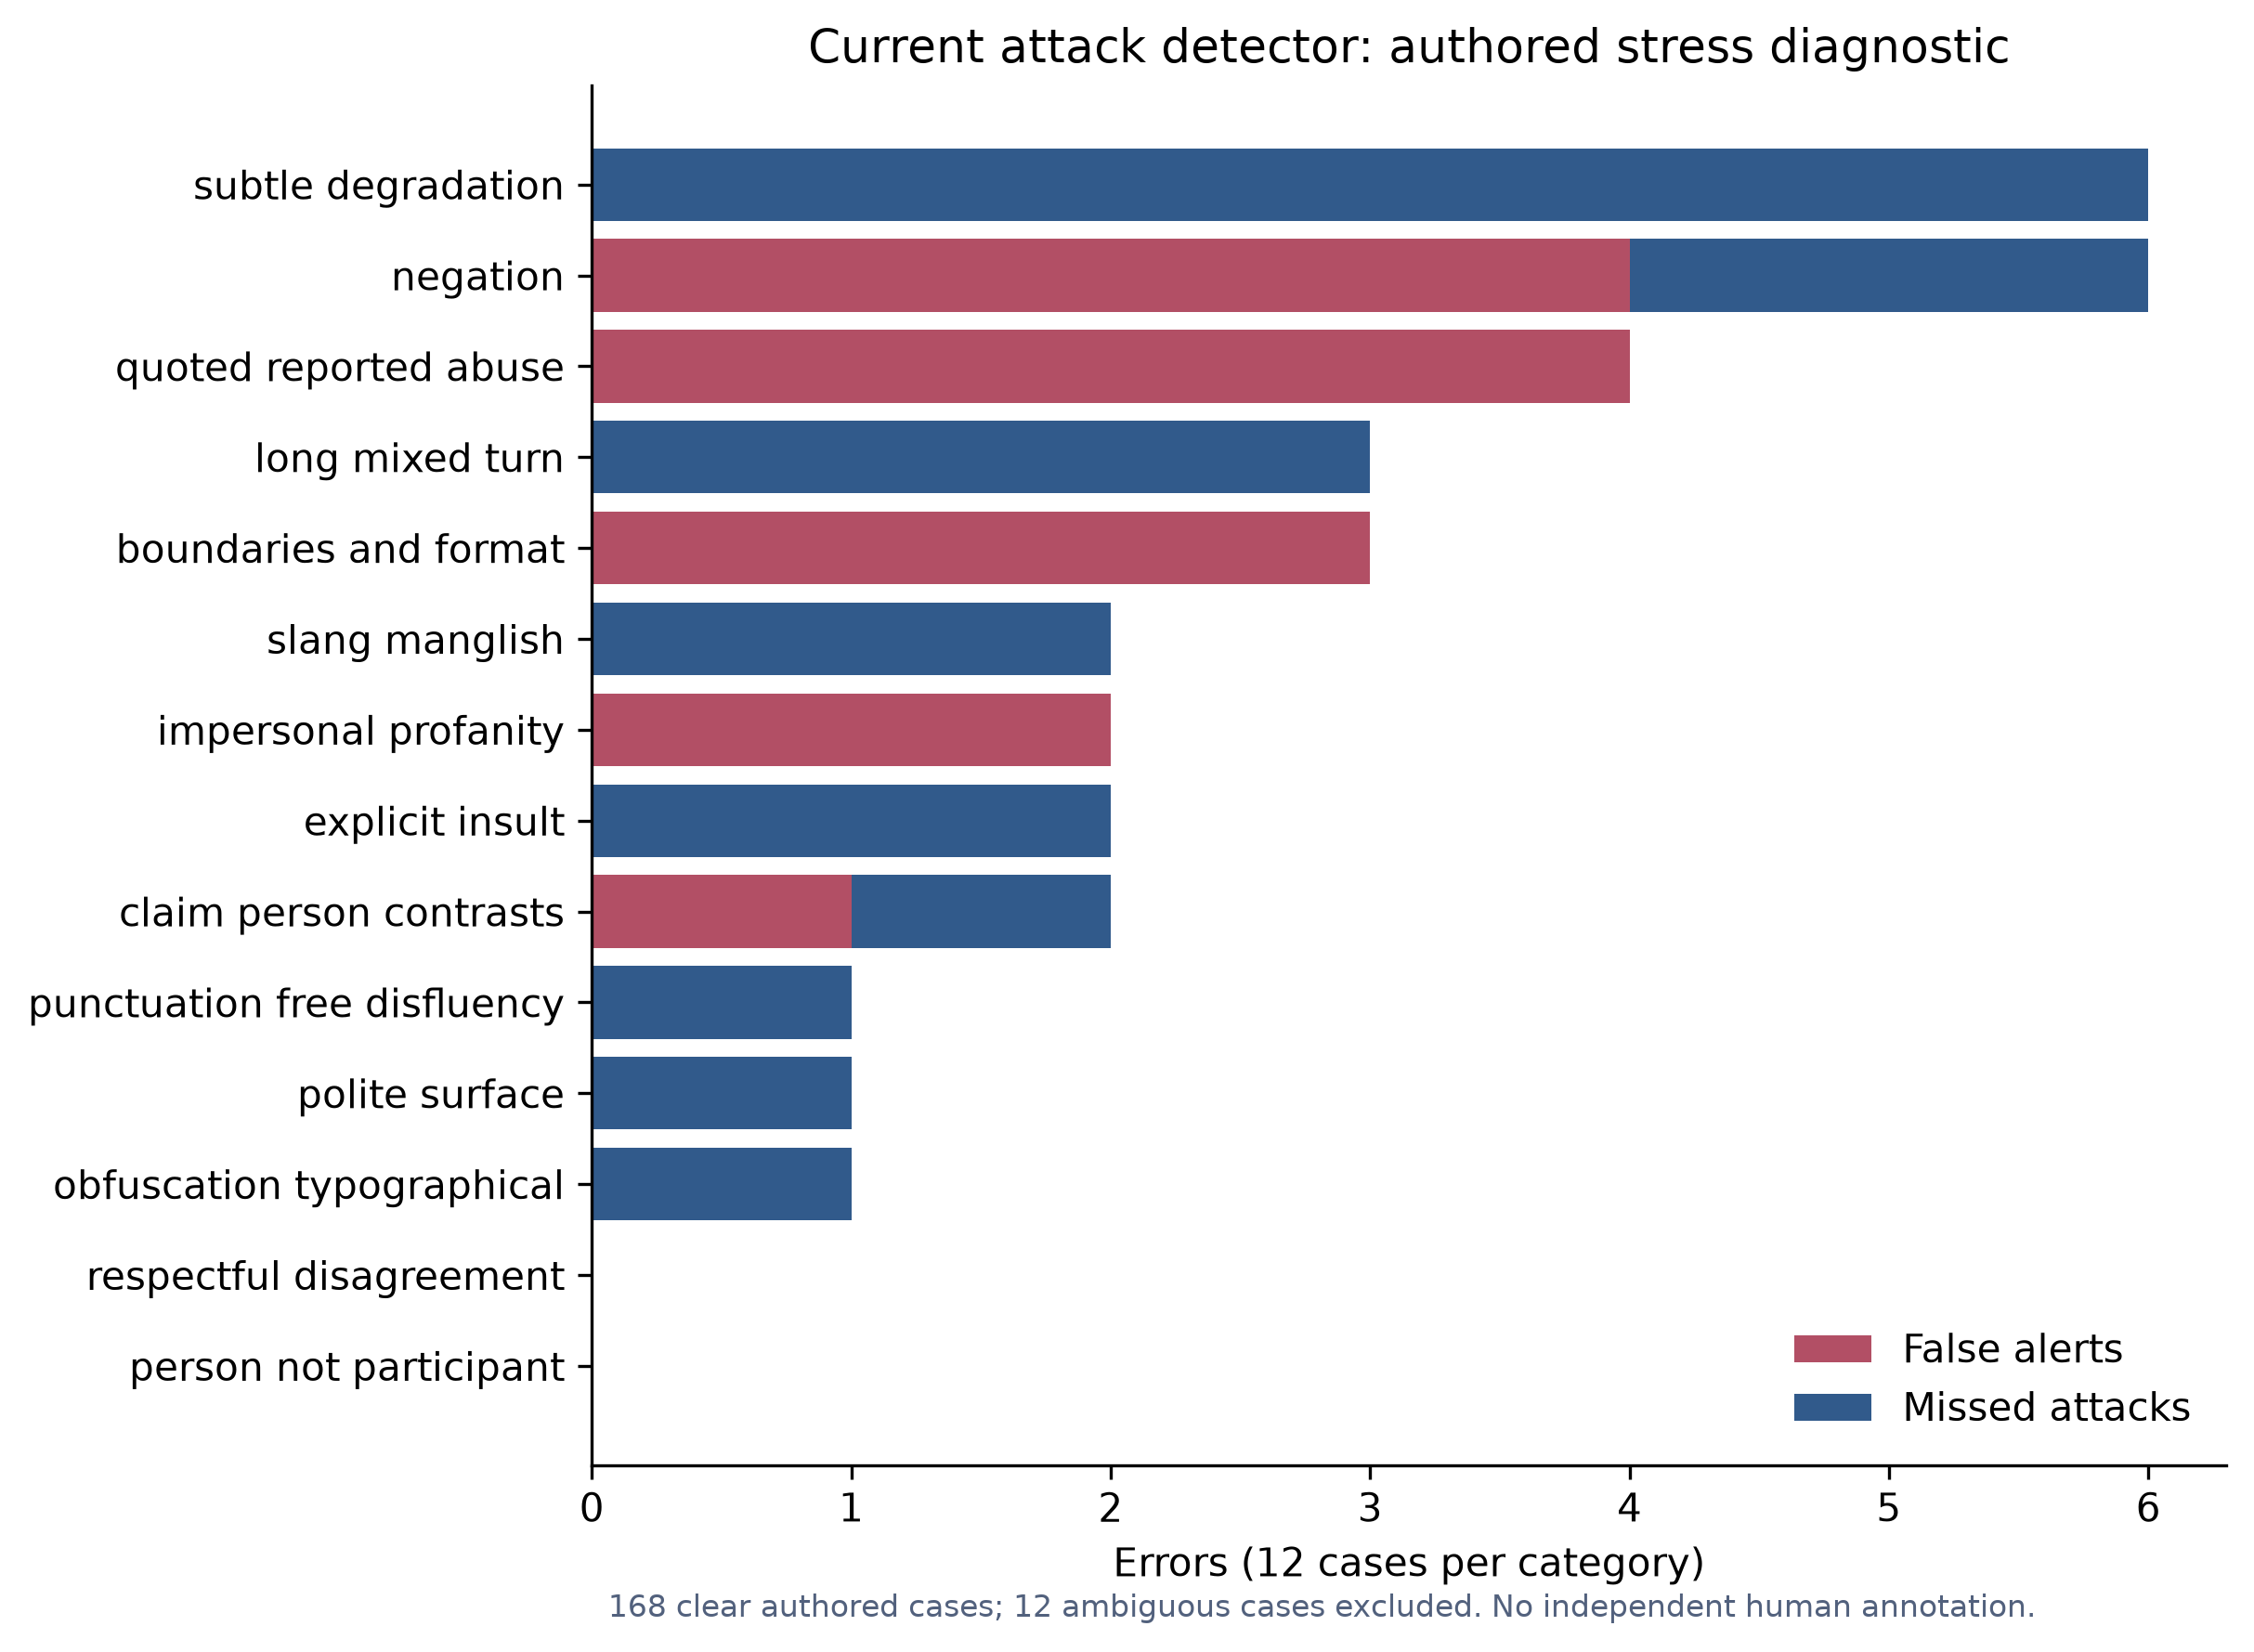

In [4]:
display(Image(filename=str(ROOT / 'reports/figures/current_attack_stress_errors.png'), width=900))


### Current topic monitor episode errors; authored diagnostic.


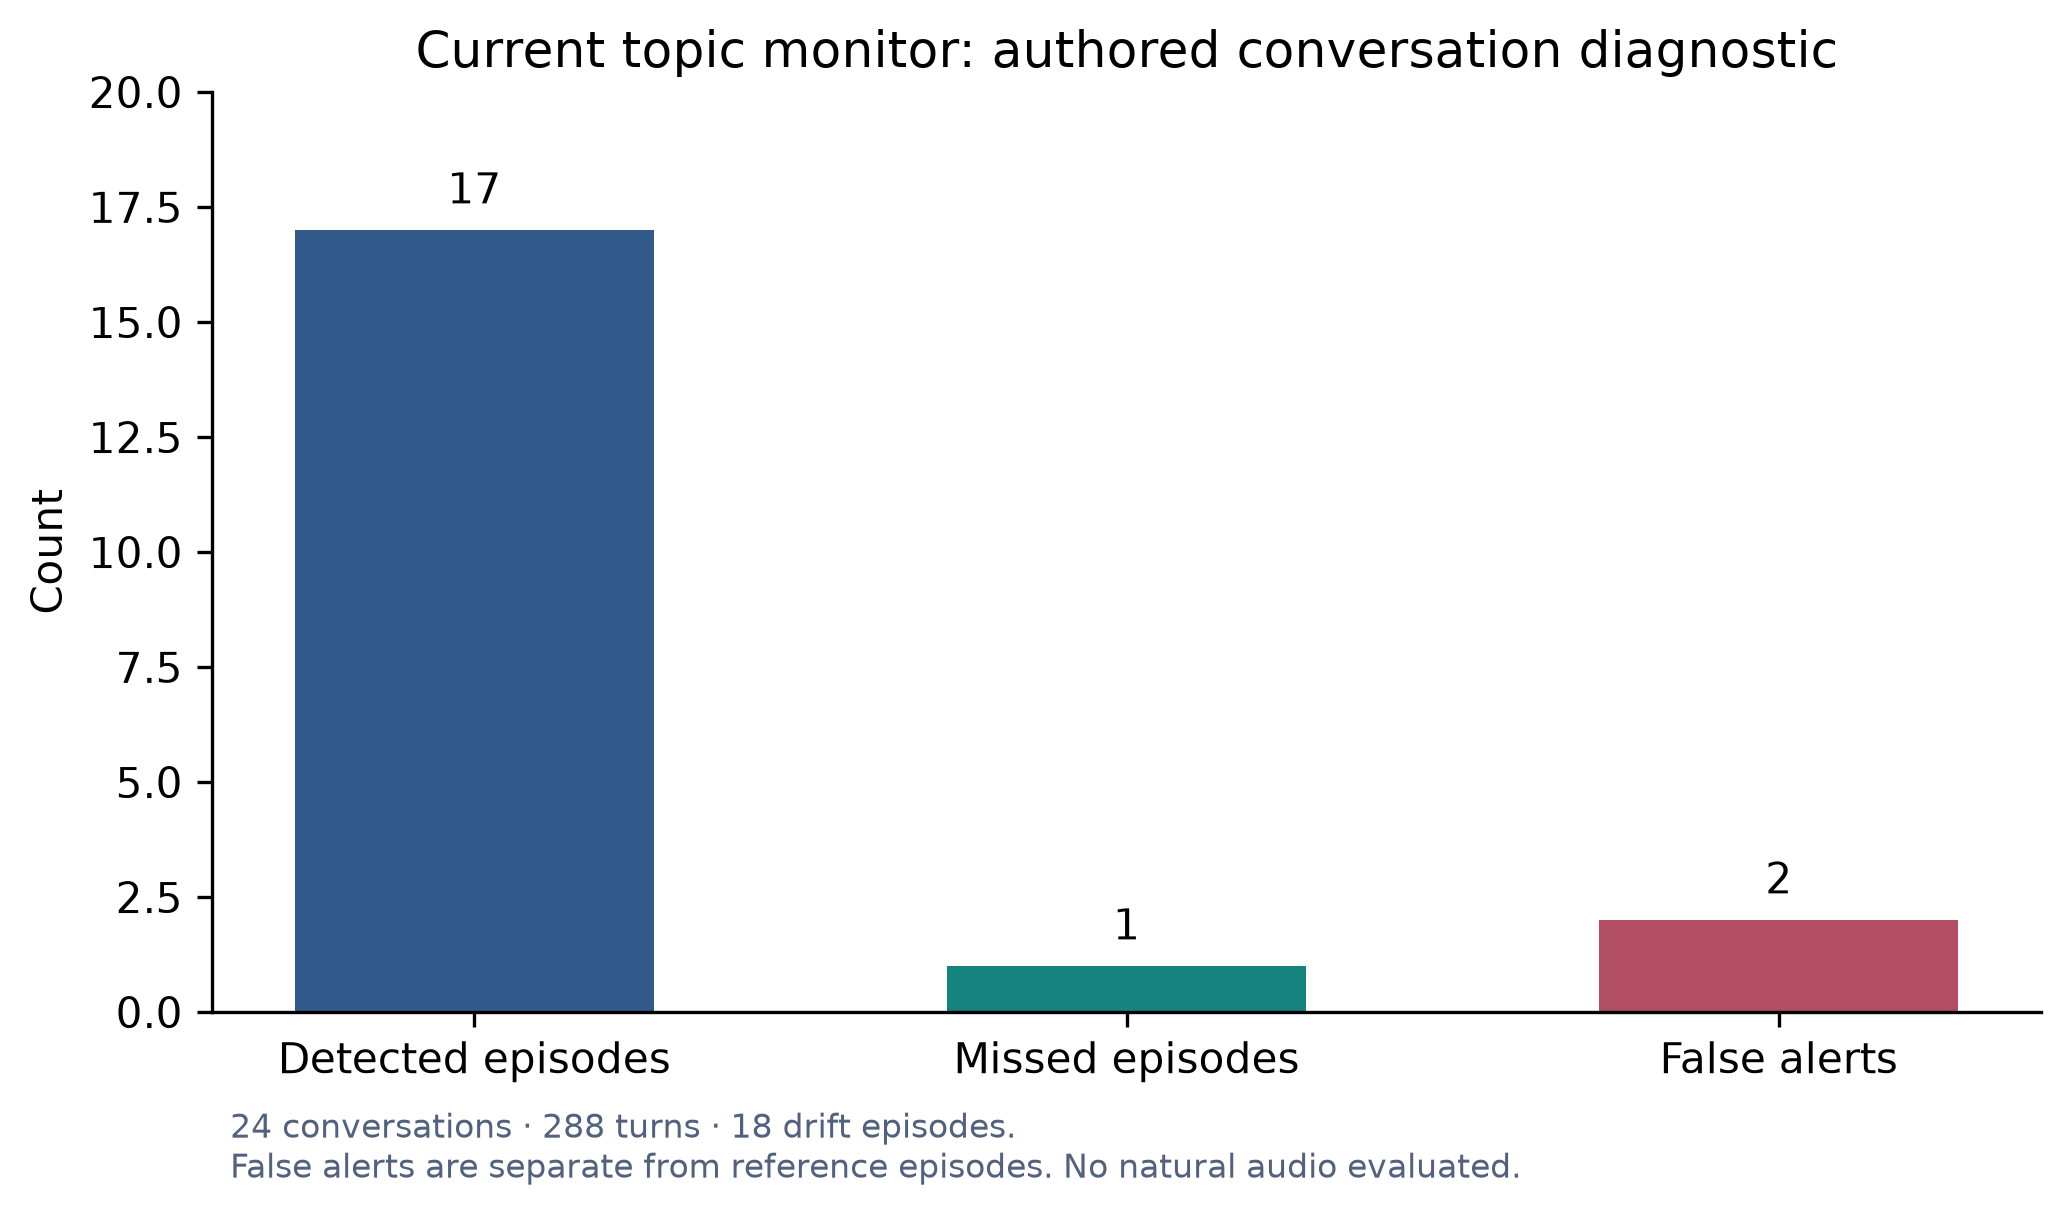

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/current_topic_episode_results.png'), width=900))


### Local feasibility benchmark; not accuracy evaluation.


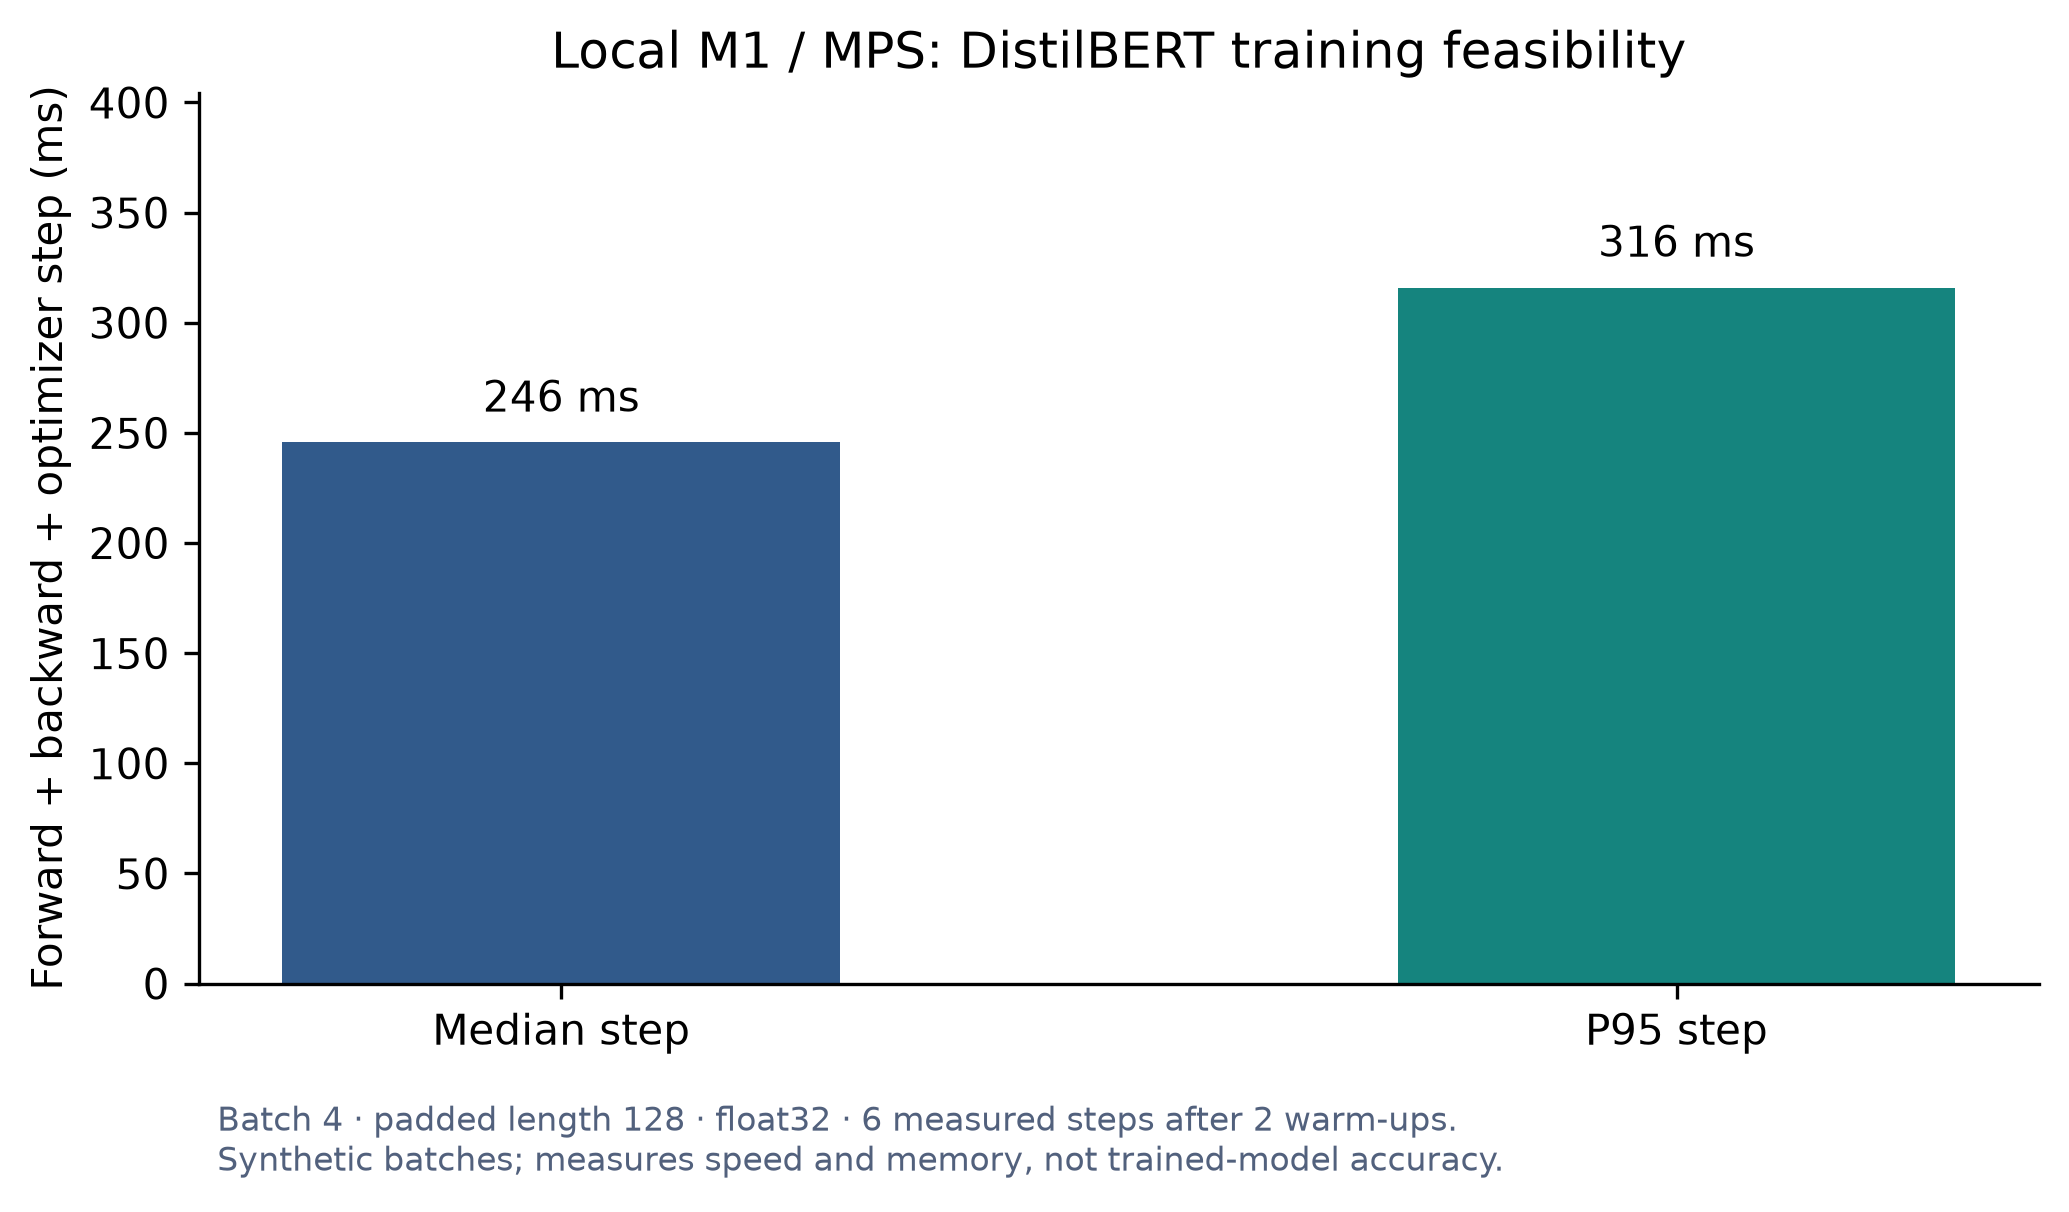

In [6]:
display(Image(filename=str(ROOT / 'reports/figures/local_mps_training_benchmark.png'), width=900))


## Reproduce locally

From the project root:

```sh
uv run --python 3.13 --with-requirements requirements.txt python prepare_transformer_data.py
HF_HUB_DISABLE_XET=1 uv run --python 3.13 --with-requirements requirements.txt python benchmark_local_training.py
uv run --python 3.13 --with-requirements requirements-training.txt python render_training_figures.py
```

Raw WikiDetox source TSVs are required under `data/raw/` and are checksum-verified. The tokenizer and pretrained weights are pinned to the revision recorded above. Local files do not automatically synchronize to Google Drive. This executed notebook can be uploaded later, preserving its saved outputs.
